In [2]:
import scimap as sm

Running SCIMAP  2.3.4


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import anndata as ad
import scanpy as sc

In [4]:
import os
os.getcwd()

'C:\\Users\\tpeng\\Notebook_home_250910'

In [8]:
adata = sc.read ('C:\\Users\\tpeng\\adata_files\\Xenium_Proseq_pt1_lesion_neighborhood.h5ad')
adata

AnnData object with n_obs × n_vars = 15871 × 475
    obs: 'cell', 'X_centroid', 'Y_centroid', 'centroid_z', 'fov', 'cluster', 'volume', 'population', 'Tissue_type', 'n_counts', 'barcode_sample', 'barcodes', 'Cell_label_L3', 'leiden', 'Section', 'imageid', 'spatial_lda_kmeans5'
    uns: 'Cell_label_L3_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'spatial_lda', 'spatial_lda_probability', 'umap'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [33]:
# run the LDA tool
adata = sm.tl.spatial_lda(adata, phenotype='Cell_label_L3', method='radius', radius=80, label='spatial_lda')

Processing: ['Pt1_lesion_proseq']
Identifying neighbours within 80 pixels of every cell
Pre-Processing Spatial LDA
Training Spatial LDA
Calculating the Coherence Score

Coherence Score:  0.28031293037437
Gathering the latent weights


C:\Users\tpeng\anaconda3\envs\scimap\lib\site-packages\scimap\tools\spatial_lda.py:270: ImplicitModificationWarning:

Trying to modify attribute `._uns` of view, initializing view as actual.



In [39]:
adata

AnnData object with n_obs × n_vars = 15871 × 475
    obs: 'cell', 'X_centroid', 'Y_centroid', 'centroid_z', 'fov', 'cluster', 'volume', 'population', 'Tissue_type', 'n_counts', 'barcode_sample', 'barcodes', 'Cell_label_L3', 'leiden', 'Section', 'imageid'
    uns: 'Cell_label_L3_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'umap', 'spatial_lda', 'spatial_lda_probability'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [41]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.colors as mcolors

In [43]:
# note that the df_name parameter needs to be the same as the label used in the previous step.
adata = sm.tl.spatial_cluster(adata, df_name='spatial_lda', method='kmeans', k=5, label='spatial_lda_kmeans5')

Kmeans clustering


In [47]:
# Let's visualize the results.

from matplotlib import rcParams
FIGSIZE = (16, 16)
my_colors = {'0':'purple', '1':'plum', '2':'olive', '3':'lightsalmon', '4':'lightsteelblue'}

sm.pl.spatial_scatterPlot(adata, colorBy='spatial_lda_kmeans5', s =4, alpha = 0.8, dpi = 300,customColors = my_colors,
                          fileName='scatterplot_pt1_lesion_IC+kera_5clusters_261002.png', saveDir="./figures")

Saved plot to ./figures\scatterplot_pt1_lesion_IC+kera_5clusters_261002.png


In [49]:
adata

AnnData object with n_obs × n_vars = 15871 × 475
    obs: 'cell', 'X_centroid', 'Y_centroid', 'centroid_z', 'fov', 'cluster', 'volume', 'population', 'Tissue_type', 'n_counts', 'barcode_sample', 'barcodes', 'Cell_label_L3', 'leiden', 'Section', 'imageid', 'spatial_lda_kmeans5'
    uns: 'Cell_label_L3_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'umap', 'spatial_lda', 'spatial_lda_probability'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [51]:
adata.write_h5ad ('C:\\Users\\tpeng\\Documents\\Spatial\\adata_files\\Xenium_Proseq_pt1_lesion_neighborhood.h5ad')

## generate heamaps ##

In [5]:
adata = sc.read ('C:\\Users\\tpeng\\adata_files\\Xenium_Proseq_pt1_lesion_neighborhood.h5ad')

In [6]:
adata

AnnData object with n_obs × n_vars = 15871 × 475
    obs: 'cell', 'X_centroid', 'Y_centroid', 'centroid_z', 'fov', 'cluster', 'volume', 'population', 'Tissue_type', 'n_counts', 'barcode_sample', 'barcodes', 'Cell_label_L3', 'leiden', 'Section', 'imageid', 'spatial_lda_kmeans5'
    uns: 'Cell_label_L3_colors', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'spatial_lda', 'spatial_lda_probability', 'umap'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [7]:
adata.obs.imageid.unique()

['Pt1_lesion_proseq']
Categories (1, object): ['Pt1_lesion_proseq']

In [10]:
df = adata.obs.groupby("Cell_label_L3")["spatial_lda_kmeans5"].value_counts().unstack()
df

C:\Users\tpeng\AppData\Local\Temp\ipykernel_25808\1557046574.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df = adata.obs.groupby("Cell_label_L3")["spatial_lda_kmeans5"].value_counts().unstack()


spatial_lda_kmeans5,0,1,2,3,4
Cell_label_L3,,,,,
Basal keratinocyte_ulc,796,4,286,9,3
Basal keratinocyte_adj,85,0,442,0,0
CD4 T cell_FOXP3+,112,318,9,270,112
CD4 T cell_GZMBhi,90,126,1,191,48
CD8 T cell_GZMBhi,493,291,62,378,239
CD8 T cell_GZMBlow,63,1999,6,737,500
DC,67,158,30,23,284
DC_LAMP3+,127,113,2,155,49
Granulosum keratinocyte_CXCL8+,197,0,4,0,0


In [11]:
frequency_table = (df / df.sum())*100
pd.options.display.float_format = '{:.2f}'.format
frequency_table

spatial_lda_kmeans5,0,1,2,3,4
Cell_label_L3,,,,,
Basal keratinocyte_ulc,25.40,0.08,17.10,0.27,0.10
Basal keratinocyte_adj,2.71,0.00,26.42,0.00,0.00
CD4 T cell_FOXP3+,3.57,6.60,0.54,8.06,3.87
CD4 T cell_GZMBhi,2.87,2.62,0.06,5.70,1.66
CD8 T cell_GZMBhi,15.73,6.04,3.71,11.29,8.25
CD8 T cell_GZMBlow,2.01,41.49,0.36,22.01,17.26
DC,2.14,3.28,1.79,0.69,9.80
DC_LAMP3+,4.05,2.35,0.12,4.63,1.69
Granulosum keratinocyte_CXCL8+,6.29,0.00,0.24,0.00,0.00


In [12]:
# Define your desired custom order
custom_order = ['0', '3', '1','2','4']
frequency_table = frequency_table[custom_order]

In [14]:
frequency_table.columns = ['N0','N1','N2','N3','N4']
frequency_table

,N0,N1,N2,N3,N4
Cell_label_L3,,,,,
Basal keratinocyte_ulc,25.40,0.27,0.08,17.10,0.10
Basal keratinocyte_adj,2.71,0.00,0.00,26.42,0.00
CD4 T cell_FOXP3+,3.57,8.06,6.60,0.54,3.87
CD4 T cell_GZMBhi,2.87,5.70,2.62,0.06,1.66
CD8 T cell_GZMBhi,15.73,11.29,6.04,3.71,8.25
CD8 T cell_GZMBlow,2.01,22.01,41.49,0.36,17.26
DC,2.14,0.69,3.28,1.79,9.80
DC_LAMP3+,4.05,4.63,2.35,0.12,1.69
Granulosum keratinocyte_CXCL8+,6.29,0.00,0.00,0.24,0.00


In [15]:
list2 = ['Granulosum keratinocyte_CXCL8+',
 'Spinosum keratinocyte_CXCL8+',
 'Basal keratinocyte_ulc',
 'Granulosum keratinocyte_KRT2+',
 'Spinosum keratinocyte_KRT2+',
 'Basal keratinocyte_adj',
 'CD8 T cell_GZMBhi',
 'CD4 T cell_GZMBhi',
 'CD8 T cell_GZMBlow',
 'CD4 T cell_FOXP3+',
 'NK cell',
 'Mono_IL3RA+',
 'Mono_ISGhi','Mono_ISGlow',
 'Mac_ISGhi',
 'Mac_ISGlow',
 'DC_LAMP3+',
 'DC',
 'PDC']

In [16]:
len(list2)

19

In [18]:
frequency_table.shape

(19, 5)

In [19]:
# Define your desired custom order
custom_order = list2
# Reorder the index based on the list
frequency_table = frequency_table.reindex(custom_order)
frequency_table

,N0,N1,N2,N3,N4
Cell_label_L3,,,,,
Granulosum keratinocyte_CXCL8+,6.29,0.00,0.00,0.24,0.00
Spinosum keratinocyte_CXCL8+,8.90,0.00,0.02,2.27,0.00
Basal keratinocyte_ulc,25.40,0.27,0.08,17.10,0.10
Granulosum keratinocyte_KRT2+,0.06,0.00,0.00,13.27,0.00
Spinosum keratinocyte_KRT2+,1.40,0.00,0.00,31.80,0.00
Basal keratinocyte_adj,2.71,0.00,0.00,26.42,0.00
CD8 T cell_GZMBhi,15.73,11.29,6.04,3.71,8.25
CD4 T cell_GZMBhi,2.87,5.70,2.62,0.06,1.66
CD8 T cell_GZMBlow,2.01,22.01,41.49,0.36,17.26


In [20]:
frequency_table.index = ['Granu kera_CXCL8+',
 'Spino kera_CXCL8+',
 'Basa kera_ulc',
 'Granu kera_KRT2+',
 'Spino kera_KRT2+',
 'Basa kera_adj',
 'CD8 T_GZMBhi',
 'CD4 T_GZMBhi',
 'CD8 T_GZMBlow',
 'CD4 T_FOXP3+',
 'NK',
 'Mono_IL3RA+',
 'Mono_ISGhi','Mono_ISGlow',
 'Mac_ISGhi','Mac_ISGlow',
 'DC_LAMP3+',
 'DC',
 'PDC']
frequency_table

,N0,N1,N2,N3,N4
Granu kera_CXCL8+,6.29,0.00,0.00,0.24,0.00
Spino kera_CXCL8+,8.90,0.00,0.02,2.27,0.00
Basa kera_ulc,25.40,0.27,0.08,17.10,0.10
Granu kera_KRT2+,0.06,0.00,0.00,13.27,0.00
Spino kera_KRT2+,1.40,0.00,0.00,31.80,0.00
Basa kera_adj,2.71,0.00,0.00,26.42,0.00
CD8 T_GZMBhi,15.73,11.29,6.04,3.71,8.25
CD4 T_GZMBhi,2.87,5.70,2.62,0.06,1.66
CD8 T_GZMBlow,2.01,22.01,41.49,0.36,17.26
CD4 T_FOXP3+,3.57,8.06,6.60,0.54,3.87


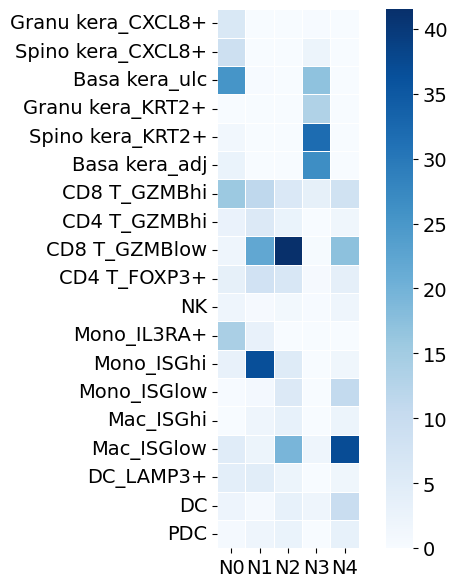

In [21]:
plt.figure(figsize=(7, 7)) # Optional: Adjust the size of the plot

ax = sns.heatmap(
    data= frequency_table,          # The DataFrame/data to plot
    annot=False,               # Display the correlation values on the heatmap
    cmap='Blues',          # The color map (e.g., 'viridis', 'plasma', 'coolwarm')
    fmt=".2f",                # String format for annotation values
    linewidths=.5,            # Space between cells
    annot_kws={"fontsize": 16}, square = True
)


# Set the font size for the x and y tick labels
ax.set_xticklabels(ax.get_xticklabels(), fontsize=14)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=14)


# Access the colorbar and set the size of its tick labels
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=14) # 'labelsize' parameter sets the tick label font size

plt.show()

In [9]:
adata.obs.imageid.unique()

['Pt1_lesion_proseq']
Categories (1, object): ['Pt1_lesion_proseq']